In [1]:
if(!require("pacman")) install.packages("pacman")
pacman::p_load(knitr, arrow, gt, ggsci, binom, tidyverse)

Loading required package: pacman



# Data

The pipeline only analyses visits that have a triage acuity score, because the Triage-Acuity
algorithm cannot be computed without one. This notebook is about the visits that get dropped
by that: who they are, and whether losing them changes anything.

- **Excluded** are the 6,984 visits the analysis filter drops (6,934 with no triage acuity score, 50 with no age) and **Retained** are the 417,723 it keeps, which is every eligible visit before the one-visit-per-patient restriction.


In [2]:
ed_data <- read_parquet("../MIMICED/ed_join_cc.parquet") |>
  # Ill only keep some columns for this analysis
  select(
    subject_id, stay_id, in_year,
    age, gender, race,
    acuity, temperature, heartrate, resprate, o2sat, sbp, dbp, pain,
    chiefcomplaint, disposition,
    icd_chapter, primary_code, length_of_stay,
    nyu, res, acuity_out
  ) |>
  # the exclusion the analysis notebook applies, kept as a flag instead of a filter
  mutate(
    kept  = !is.na(acuity) & !is.na(age) & !is.na(race),
    group = if_else(kept, "Retained", "Excluded")
  )

dim(ed_data)

[1] 424707     24

Check the counts before I do anything with them.

In [3]:
checks <- tribble(
  ~check,                    ~expected, ~observed,
  "All visits",                 424707, nrow(ed_data),
  "Retained by the filter",     417723, sum(ed_data$kept),
  "Excluded by the filter",       6984, sum(!ed_data$kept),
  "Missing acuity",               6934, sum(is.na(ed_data$acuity)),
  "Missing age",                    50, sum(is.na(ed_data$age)),
  "Missing race",                    0, sum(is.na(ed_data$race))
) |>
  mutate(result = if_else(expected == observed, "PASS", "FAIL"))

checks |> kable()

if (any(checks$result == "FAIL")) stop("Counts don't match - stop and work out why before going on")

# carry the two denominators around
n_ex  <- sum(!ed_data$kept)
n_re  <- sum(ed_data$kept)
n_acu <- sum(is.na(ed_data$acuity))



|check                  | expected| observed|result |
|:----------------------|--------:|--------:|:------|
|All visits             |   424707|   424707|PASS   |
|Retained by the filter |   417723|   417723|PASS   |
|Excluded by the filter |     6984|     6984|PASS   |
|Missing acuity         |     6934|     6934|PASS   |
|Missing age            |       50|       50|PASS   |
|Missing race           |        0|        0|PASS   |

# Excluded vs retained

The exclusion could bias the whole study, so the first question is whether the visits it removes
are a different kind of visit from the ones I keep. The groups are large enough that everything is
significant, so I use standardised mean differences instead of p-values, with the usual
|SMD| > 0.1 threshold.

In [4]:
# SMD, excluded minus retained
smd_cont <- function(m1, s1, m2, s2) (m1 - m2) / sqrt((s1^2 + s2^2) / 2)
smd_prop <- function(p1, p2)         (p1 - p2) / sqrt((p1 * (1 - p1) + p2 * (1 - p2)) / 2)

# large-sample SE of an SMD (Hedges & Olkin), valid for the continuous and the binary case alike
se_smd <- function(d, n1, n2) {
  # as.numeric matters: n1 * n2 overflows R's 32-bit integer and returns NA
  n1 <- as.numeric(n1); n2 <- as.numeric(n2)
  sqrt((n1 + n2) / (n1 * n2) + d^2 / (2 * (n1 + n2)))
}

cont_compare <- function(var, label, dp = 1) {
  s <- ed_data |>
    group_by(group) |>
    summarise(
      n_obs = sum(!is.na(.data[[var]])),
      mean  = mean(.data[[var]], na.rm = T),
      sd    = sd(.data[[var]], na.rm = T),
      med   = median(.data[[var]], na.rm = T),
      q1    = quantile(.data[[var]], 0.25, na.rm = T),
      q3    = quantile(.data[[var]], 0.75, na.rm = T),
      .groups = "drop"
    )
  e <- s |> filter(group == "Excluded")
  r <- s |> filter(group == "Retained")
  tibble(
    level    = label,
    dp       = dp,
    n_obs_ex = e$n_obs, mean_ex = e$mean, sd_ex = e$sd, med_ex = e$med, q1_ex = e$q1, q3_ex = e$q3,
    n_obs_re = r$n_obs, mean_re = r$mean, sd_re = r$sd, med_re = r$med, q1_re = r$q1, q3_re = r$q3,
    smd      = smd_cont(e$mean, e$sd, r$mean, r$sd)
  ) |>
    mutate(
      smd_lower = smd - 1.96 * se_smd(smd, n_ex, n_re),
      smd_upper = smd + 1.96 * se_smd(smd, n_ex, n_re)
    )
}

# proportions are of the whole group, so NAs would show as their own level
cat_compare <- function(var) {
  ed_data |>
    mutate(level = as.character(.data[[var]])) |>
    count(group, level) |>
    pivot_wider(names_from = group, values_from = n, values_fill = 0L) |>
    rename(n_excluded = Excluded, n_retained = Retained) |>
    mutate(
      prop_excluded = n_excluded / n_ex,
      prop_retained = n_retained / n_re,
      smd        = smd_prop(prop_excluded, prop_retained),
      smd_lower  = smd - 1.96 * se_smd(smd, n_ex, n_re),
      smd_upper  = smd + 1.96 * se_smd(smd, n_ex, n_re)
    ) |>
    arrange(desc(n_excluded))
}

The 0.1 threshold is a convention, not a boundary, and a few of these rows sit close enough to it
that the estimate on its own would make the call look more clear-cut than it is. So I carry a 95%
interval on every standardised difference.


Collapse race and gender the same way `3_descriptive.ipynb` does, so the categories line up with
table 1.

In [5]:
disp_labels <- c(
  "HOME"                        = "Home",
  "ADMITTED"                    = "Admitted",
  "TRANSFER"                    = "Transfer",
  "EXPIRED"                     = "Expired",
  "LEFT WITHOUT BEING SEEN"     = "Left without being seen",
  "ELOPED"                      = "Eloped",
  "LEFT AGAINST MEDICAL ADVICE" = "Left against medical advice",
  "OTHER"                       = "Other"
)

ed_data <- ed_data |>
  mutate(
    disp_l = unname(disp_labels[disposition]),
    race_grp = case_when(
      str_detect(race, "WHITE")    ~ "White",
      str_detect(race, "BLACK")    ~ "Black",
      str_detect(race, "HISPANIC") ~ "Hispanic/Latino",
      str_detect(race, "ASIAN")    ~ "Asian",
      T                            ~ "Other"
    ),
    gender_lab = case_when(
      gender == "M" ~ "Male",
      gender == "F" ~ "Female"
    )
  )

In [6]:
cont_tbl <- bind_rows(
  cont_compare("age", "Age", dp = 1),
  cont_compare("length_of_stay", "Length of stay", dp = 0)
)

# each row carries its own dp, so format to text rather than round the column
cont_tbl |>
  transmute(
    level,
    n_obs_ex,
    mean_ex = sprintf(paste0("%.", dp, "f"), mean_ex),
    sd_ex   = sprintf(paste0("%.", dp, "f"), sd_ex),
    med_ex  = sprintf(paste0("%.", dp, "f"), med_ex),
    mean_re = sprintf(paste0("%.", dp, "f"), mean_re),
    sd_re   = sprintf(paste0("%.", dp, "f"), sd_re),
    med_re  = sprintf(paste0("%.", dp, "f"), med_re),
    smd       = sprintf("%+.3f", smd),
    smd_lower = sprintf("%.3f", smd_lower),
    smd_upper = sprintf("%.3f", smd_upper)
  ) |>
  kable()




|level          | n_obs_ex|mean_ex |sd_ex |med_ex |mean_re |sd_re |med_re |smd    |smd_lower |smd_upper |
|:--------------|--------:|:-------|:-----|:------|:-------|:-----|:------|:------|:---------|:---------|
|Age            |     6934|54.5    |21.4  |55.0   |52.8    |20.6  |53.0   |+0.080 |0.057     |0.104     |
|Length of stay |     6970|272     |259   |221    |429     |370   |330    |-0.490 |-0.514    |-0.466    |

Age is part of the exclusion rule, so the excluded age numbers use the 6,934 that do have one.
The excluded stay is *shorter* (median 221 vs 330 minutes) - that's rapid movement out of the ED
to theatre, ICU or the mortuary, not a quick minor injury.

Pain is the one variable the study reports that I have left out of this. It is a triage field, so
it goes missing for the same reason acuity does rather than by chance - the numbers for that are in
*Why is the acuity missing?* below.

In [7]:
gender_tbl <- cat_compare("gender_lab")
race_tbl   <- cat_compare("race_grp")
dispo_tbl  <- cat_compare("disp_l")
# top 10 chapters in the excluded group only, otherwise this table is 18 rows of nothing
icd_tbl    <- cat_compare("icd_chapter") |> slice_head(n = 10)

for (tbl in list(gender_tbl, race_tbl, dispo_tbl, icd_tbl)) {
  tbl |>
    mutate(
      across(c(prop_excluded, prop_retained), \(x) round(x, 2)),
      across(c(smd, smd_lower, smd_upper), \(x) round(x, 3))
    ) |>
    kable() |> print()
}




|level  | n_excluded| n_retained| prop_excluded| prop_retained|   smd| smd_lower| smd_upper|
|:------|----------:|----------:|-------------:|-------------:|-----:|---------:|---------:|
|Male   |       4090|     190925|          0.59|          0.46|  0.26|     0.236|     0.283|
|Female |       2894|     226798|          0.41|          0.54| -0.26|    -0.283|    -0.236|


|level           | n_excluded| n_retained| prop_excluded| prop_retained|    smd| smd_lower| smd_upper|
|:---------------|----------:|----------:|-------------:|-------------:|------:|---------:|---------:|
|White           |       3332|     242486|          0.48|          0.58| -0.208|    -0.232|    -0.185|
|Other           |       2244|      30755|          0.32|          0.07|  0.655|     0.631|     0.678|
|Black           |        835|      92065|          0.12|          0.22| -0.271|    -0.295|    -0.247|
|Hispanic/Latino |        367|      34113|          0.05|          0.08| -0.117|    -0.140|    -0.093|
|Asian

The 'Other' race row jumps out - 32.1% of the excluded against 7.4% retained. Worth checking the
raw strings before I read anything into it.

In [8]:
ed_data |>
  filter(!kept) |>
  count(race, sort = T) |>
  mutate(percentage = round(n / n_ex * 100, 2)) |>
  slice_head(n = 8) |>
  kable()

ed_data |>
  group_by(group) |>
  summarise(
    `unidentified (%)` = round(mean(race %in% c("UNKNOWN", "UNABLE TO OBTAIN", "PATIENT DECLINED TO ANSWER")) * 100, 2)
  ) |>
  kable()



|race                           |    n| percentage|
|:------------------------------|----:|----------:|
|WHITE                          | 3151|      45.12|
|UNKNOWN                        | 1624|      23.25|
|BLACK/AFRICAN AMERICAN         |  685|       9.81|
|OTHER                          |  403|       5.77|
|HISPANIC/LATINO - PUERTO RICAN |  124|       1.78|
|UNABLE TO OBTAIN               |  108|       1.55|
|ASIAN                          |   79|       1.13|
|ASIAN - CHINESE                |   77|       1.10|



|group    | unidentified (%)|
|:--------|----------------:|
|Excluded |            25.16|
|Retained |             1.48|

As I thought - 25.2% of the excluded are UNKNOWN or UNABLE TO OBTAIN against 1.5% retained, and
those collapse into 'Other'. It's unidentified critically ill patients, not a real ethnic
difference.

## Table 1

In [9]:
fmt_np <- function(n, p) sprintf("%s (%.2f)", formatC(n, format = "d", big.mark = ","), p * 100)
# age reads to one decimal, length of stay to none
fmt_ms <- function(m, s, dp) sprintf(paste0("%.", dp, "f (%.", dp, "f)"), m, s)

cat_rows <- function(tbl, var_label) {
  tbl |>
    transmute(
      variable = var_label,
      level,
      Excluded = fmt_np(n_excluded, prop_excluded),
      Retained = fmt_np(n_retained, prop_retained),
      SMD      = sprintf("%+.3f [%.3f, %.3f]", smd, smd_lower, smd_upper)
    )
}

table_1 <- bind_rows(
  cont_tbl |>
    transmute(
      variable = "Continuous, mean (SD)",
      level,
      Excluded = fmt_ms(mean_ex, sd_ex, dp),
      Retained = fmt_ms(mean_re, sd_re, dp),
      SMD      = sprintf("%+.3f [%.3f, %.3f]", smd, smd_lower, smd_upper)
    ),
  cat_rows(gender_tbl, "Sex, n (%)"),
  cat_rows(race_tbl,   "Race, n (%)"),
  cat_rows(dispo_tbl,  "Disposition, n (%)"),
  cat_rows(icd_tbl,    "ICD chapter, n (%)")
)

# the docx keeps the grouping column, I don't need it to eyeball this
table_1 |> select(-variable) |> kable()



|level                                                          |Excluded      |Retained        |SMD                     |
|:--------------------------------------------------------------|:-------------|:---------------|:-----------------------|
|Age                                                            |54.5 (21.4)   |52.8 (20.6)     |+0.080 [0.057, 0.104]   |
|Length of stay                                                 |272 (259)     |429 (370)       |-0.490 [-0.514, -0.466] |
|Male                                                           |4,090 (58.56) |190,925 (45.71) |+0.260 [0.236, 0.283]   |
|Female                                                         |2,894 (41.44) |226,798 (54.29) |-0.260 [-0.283, -0.236] |
|White                                                          |3,332 (47.71) |242,486 (58.05) |-0.208 [-0.232, -0.185] |
|Other                                                          |2,244 (32.13) |30,755 (7.36)   |+0.655 [0.631, 0.678]   |
|Black        

In [10]:
table_1 |>
  kable()

table_1 |>
  gt(rowname_col = "level", groupname_col = "variable") |>
  cols_label(
    Excluded = sprintf("Excluded (n = %s)", formatC(n_ex, format = "d", big.mark = ",")),
    Retained = sprintf("Retained (n = %s)", formatC(n_re, format = "d", big.mark = ",")),
    SMD      = "SMD [95% CI]"
  ) |>
  tab_source_note(
    "SMD is excluded minus retained. Percentages are of the whole group. ICD chapters are the ten most common among the excluded, so they do not sum to 100%."
  ) |>
  gtsave(filename = "s1_table_1.docx")



|variable              |level                                                          |Excluded      |Retained        |SMD                     |
|:---------------------|:--------------------------------------------------------------|:-------------|:---------------|:-----------------------|
|Continuous, mean (SD) |Age                                                            |54.5 (21.4)   |52.8 (20.6)     |+0.080 [0.057, 0.104]   |
|Continuous, mean (SD) |Length of stay                                                 |272 (259)     |429 (370)       |-0.490 [-0.514, -0.466] |
|Sex, n (%)            |Male                                                           |4,090 (58.56) |190,925 (45.71) |+0.260 [0.236, 0.283]   |
|Sex, n (%)            |Female                                                         |2,894 (41.44) |226,798 (54.29) |-0.260 [-0.283, -0.236] |
|Race, n (%)           |White                                                          |3,332 (47.71) |242,486 (58.05) |-0

# Figure 1

I use the JAMA palette to match figure 1 in the main analysis.

In [11]:
jama_palette <- ggsci::pal_jama()(7)

# shared by both figures
s1_theme <- theme_minimal() +
  theme(
    panel.grid      = element_blank(),
    axis.line       = element_line(color = "black"),
    legend.position = "bottom",
    axis.text       = element_text(size = rel(1.1), colour = "black", face = "bold"),
    axis.title      = element_text(size = rel(1.3), colour = "black", face = "bold"),
    legend.text     = element_text(size = rel(1.1), colour = "black", face = "bold")
  )


Warning message:
“`geom_errorbarh()` was deprecated in ggplot2 4.0.0.
ℹ Please use the `orientation` argument of `geom_errorbar()` instead.”


`height` was translated to `width`.


`height` was translated to `width`.


`height` was translated to `width`.


`height` was translated to `width`.


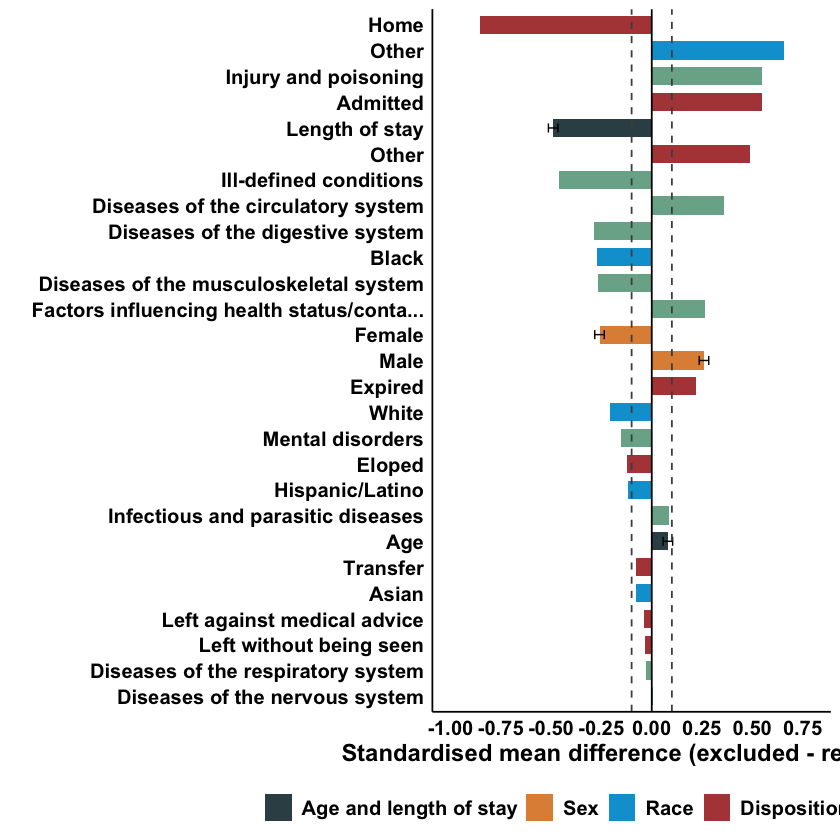

In [12]:
smd_data <- bind_rows(
  cont_tbl   |> transmute(level, variable = "Age and length of stay", smd, smd_lower, smd_upper),
  gender_tbl |> transmute(level, variable = "Sex", smd, smd_lower, smd_upper),
  race_tbl   |> transmute(level, variable = "Race", smd),
  dispo_tbl  |> transmute(level, variable = "Disposition", smd),
  icd_tbl    |> transmute(level, variable = "ICD chapter", smd)
) |>
  mutate(
    label    = str_trunc(level, 42),
    variable = factor(variable, levels = c("Age and length of stay", "Sex", "Race",
                                           "Disposition", "ICD chapter"))
  ) |>
  arrange(abs(smd)) |>
  # 'Other' is a level of both race and disposition, so the label alone is not a unique key
  mutate(id = factor(row_number(), levels = row_number()))

figure_1 <- smd_data |>
  ggplot(aes(x = smd, y = id, fill = variable)) +
  geom_col(width = 0.7) +
  geom_errorbarh(aes(xmin = smd_lower, xmax = smd_upper), height = 0.35, linewidth = 0.4, colour = "black") +
  geom_vline(xintercept = 0, colour = "black") +
  geom_vline(xintercept = c(-0.1, 0.1), linetype = "dashed", colour = "grey30") +
  scale_x_continuous(limits = c(-1, 0.8), breaks = seq(-1, 0.75, 0.25)) +
  scale_y_discrete(labels = setNames(smd_data$label, as.character(smd_data$id))) +
  scale_fill_manual(values = jama_palette[1:5]) +
  labs(
    x    = "Standardised mean difference (excluded - retained)",
    y    = "",
    fill = ""
  ) +
  s1_theme

ggsave("s1_figure_1.png", plot = figure_1, device = "png", width = 12, height = 11, units = "in", dpi = 600)
ggsave("s1_figure_1.svg", plot = figure_1, device = "svg", width = 12, height = 11, units = "in")
ggsave("s1_figure_1.pdf", plot = figure_1, device = "pdf", width = 12, height = 11, units = "in")

figure_1

Everything past the dashed line is one underlying difference said several ways: these patients
were admitted or died rather than going home, and they carry injury and circulatory codes rather
than the ill-defined ones that dominate the retained visits.

Age is the row to be careful with. The interval runs to just past 0.1, so I can't call it clearly
under the threshold - but 54.5 against 52.8 years is 1.7 years, which is not a difference that
means anything clinically. The threshold isn't what settles that one, the size is.


# Why is the acuity missing?

That is the *what*. Now the *why*, because it is what explains the pattern in table 1. The filter
has three conditions in it, so first I want to know which one is actually doing the excluding.

In [13]:
ed_data |>
  filter(!kept) |>
  mutate(
    pattern = case_when(
      is.na(acuity) & is.na(age) ~ "acuity + age",
      is.na(acuity)              ~ "acuity only",
      is.na(age)                 ~ "age only",
      T                          ~ "race only"
    )
  ) |>
  count(pattern, sort = T) |>
  mutate(percentage = round(n / n_ex * 100, 2)) |>
  kable()



|pattern     |    n| percentage|
|:-----------|----:|----------:|
|acuity only | 6934|      99.28|
|age only    |   50|       0.72|

So this is one exclusion, not three. 6,934 visits go because acuity is missing, 50 because age
is missing, none because of race. The conditions don't compound.

Acuity (ESI) is assigned by the nurse at triage. If that assessment never happened then there
is no acuity score - and there shouldn't be any of the other triage observations either. That is
testable: compare the completeness of the other seven triage fields with and without a score.

In [14]:
triage_fields <- c("temperature", "heartrate", "resprate", "o2sat", "sbp", "dbp", "pain")

triage_done <- ed_data |>
  mutate(
    n_vitals = rowSums(!is.na(across(all_of(triage_fields)))),
    triage   = if_else(is.na(acuity), "No acuity score", "Acuity recorded")
  ) |>
  group_by(triage) |>
  summarise(
    n                = n(),
    `No vitals (%)`  = round(mean(n_vitals == 0) * 100, 2),
    `Mean vitals /7` = round(mean(n_vitals), 2),
    `No HR (%)`      = round(mean(is.na(heartrate)) * 100, 2),
    `No pain (%)`    = round(mean(is.na(pain)) * 100, 2),
    `Has CC (%)`     = round(mean(!is.na(chiefcomplaint) & str_trim(chiefcomplaint) != "") * 100, 2),
    .groups = "drop"
  )

triage_done |> kable()



|triage          |      n| No vitals (%)| Mean vitals /7| No HR (%)| No pain (%)| Has CC (%)|
|:---------------|------:|-------------:|--------------:|---------:|-----------:|----------:|
|Acuity recorded | 417773|          1.57|           6.76|      2.47|        4.85|     100.00|
|No acuity score |   6934|         96.73|           0.18|     97.35|       97.27|      99.91|

That's the answer. 96.7% of them have none of the seven triage vitals at all, and on average
0.18 of 7 are present against 6.76 for everyone else. But 99.9% still have a chief complaint,
so these are real encounters that were logged - the triage *step* was skipped, the record
wasn't lost.

`pain` is a triage field too, so it goes the same way the acuity score does - only 2.7% of the
visits with no acuity score have a pain score recorded, against 95.1% of the rest. That is the
evidence behind leaving it out of the comparison: it is missing for the same reason acuity is, not
by chance.


## Where do they concentrate

In [15]:
# rate = missing within that level; share = that level's contribution to all missing
miss_by <- function(var) {
  ed_data |>
    mutate(level = if_else(is.na(.data[[var]]), "(missing)", as.character(.data[[var]]))) |>
    group_by(level) |>
    summarise(n_all = n(), n_missing = sum(is.na(acuity)), .groups = "drop") |>
    mutate(
      `rate (%)`  = round(n_missing / n_all * 100, 2),
      `share (%)` = round(n_missing / n_acu * 100, 2)
    ) |>
    arrange(desc(n_missing))
}

miss_by("disposition") |> kable()



|level                       |  n_all| n_missing| rate (%)| share (%)|
|:---------------------------|------:|---------:|--------:|---------:|
|ADMITTED                    | 157940|      4410|     2.79|     63.60|
|HOME                        | 241439|      1307|     0.54|     18.85|
|OTHER                       |   4254|       881|    20.71|     12.71|
|EXPIRED                     |    372|       175|    47.04|      2.52|
|LEFT WITHOUT BEING SEEN     |   6139|        73|     1.19|      1.05|
|TRANSFER                    |   7018|        56|     0.80|      0.81|
|ELOPED                      |   5666|        18|     0.32|      0.26|
|LEFT AGAINST MEDICAL ADVICE |   1879|        14|     0.75|      0.20|

Admitted patients are 63.6% of everything that goes missing, and 47% of the 372 people who died
in the ED have no acuity score. The three "patient left" dispositions together account for 1.5%
of the missing, at rates at or below the overall 1.6% - so this is not people walking out before
they were seen. It's the opposite.

Last thing to rule out is that this is one era or one system change. MIMIC dates are shifted
forward by a per-patient offset so `in_year` isn't a real calendar year, and it spans 103 values.
I'll bin it into decades.

In [16]:
ed_data |>
  mutate(decade = paste0(floor(in_year / 10) * 10, "s")) |>
  group_by(decade) |>
  summarise(n_all = n(), n_missing = sum(is.na(acuity)), .groups = "drop") |>
  mutate(
    `rate (%)`  = round(n_missing / n_all * 100, 2),
    `share (%)` = round(n_missing / n_acu * 100, 2)
  ) |>
  kable()



|decade | n_all| n_missing| rate (%)| share (%)|
|:------|-----:|---------:|--------:|---------:|
|2110s  | 28758|       675|     2.35|      9.73|
|2120s  | 43946|       823|     1.87|     11.87|
|2130s  | 52739|       891|     1.69|     12.85|
|2140s  | 53833|       872|     1.62|     12.58|
|2150s  | 52003|       817|     1.57|     11.78|
|2160s  | 53015|       846|     1.60|     12.20|
|2170s  | 53351|       856|     1.60|     12.34|
|2180s  | 52752|       877|     1.66|     12.65|
|2190s  | 24746|       222|     0.90|      3.20|
|2200s  |  9406|        55|     0.58|      0.79|
|2210s  |   158|         0|     0.00|      0.00|

In [17]:
# range of the annual rate, across shifted years with a sensible number of visits
ed_data |>
  group_by(in_year) |>
  summarise(n_all = n(), rate = sum(is.na(acuity)) / n() * 100, .groups = "drop") |>
  filter(n_all >= 1000) |>
  pull(rate) |>
  range() |>
  round(2) |>
  kable()



|    x|
|----:|
| 0.50|
| 3.12|

No discontinuity anywhere - every reasonably sized shifted year sits between 0.5% and 3.1%, and
it drifts gently down over time, which is what improving triage documentation looks like.

# Figure 2

The mechanism drawn out - no triage vitals, but a chief complaint almost every time.

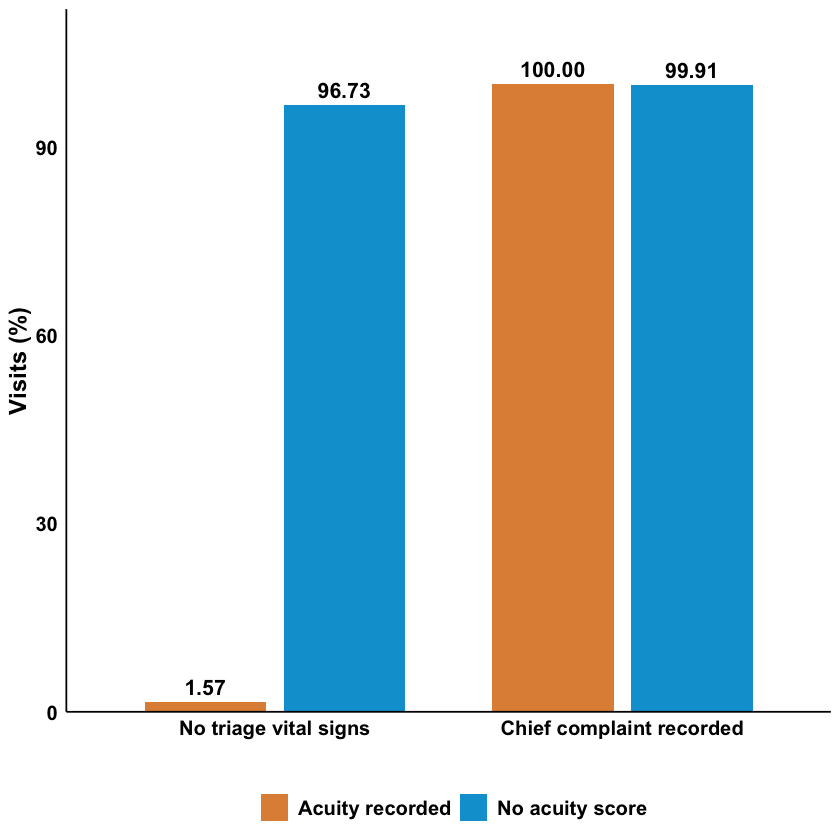

In [18]:
# the mechanism - triage never happened, but the encounter was still logged
figure_2 <- triage_done |>
  transmute(
    triage,
    `No triage vital signs`    = `No vitals (%)`,
    `Chief complaint recorded` = `Has CC (%)`
  ) |>
  pivot_longer(-triage, names_to = "measure", values_to = "pct") |>
  mutate(
    triage  = factor(triage, levels = c("Acuity recorded", "No acuity score")),
    measure = factor(measure, levels = c("No triage vital signs", "Chief complaint recorded"))
  ) |>
  ggplot(aes(x = measure, y = pct, fill = triage)) +
  geom_col(position = position_dodge(width = 0.8), width = 0.7) +
  geom_text(
    aes(label = sprintf("%.2f", pct)),
    position = position_dodge(width = 0.8),
    vjust    = -0.5,
    size     = 4.5,
    fontface = "bold"
  ) +
  scale_y_continuous(expand = expansion(mult = c(0, 0.12))) +
  scale_fill_manual(values = jama_palette[c(2, 3)]) +
  labs(
    x    = "",
    y    = "Visits (%)",
    fill = ""
  ) +
  s1_theme

ggsave("s1_figure_2.png", plot = figure_2, device = "png", width = 8, height = 6, units = "in", dpi = 600)
ggsave("s1_figure_2.svg", plot = figure_2, device = "svg", width = 8, height = 6, units = "in")
ggsave("s1_figure_2.pdf", plot = figure_2, device = "pdf", width = 8, height = 6, units = "in")

figure_2

# Can the other two algorithms still be computed?

Diagnosis only needs the primary discharge code and Resources only needs disposition, medication
and rhythm records. Neither needs a triage score, so both should still be computable here.

In [19]:
avail <- ed_data |>
  group_by(group) |>
  summarise(
    n          = n(),
    code_avail = sum(!is.na(primary_code)),
    nyu_avail  = sum(!is.na(nyu)),        nyu_flag = sum(nyu == 1, na.rm = T),
    res_avail  = sum(!is.na(res)),        res_flag = sum(res == 1, na.rm = T),
    acu_avail  = sum(!is.na(acuity_out)), acu_flag = sum(acuity_out == 1, na.rm = T),
    .groups = "drop"
  )

# percentage non-missing in each group
avail |>
  transmute(
    group,
    n,
    primary_code = round(code_avail / n * 100, 2),
    nyu          = round(nyu_avail / n * 100, 2),
    res          = round(res_avail / n * 100, 2),
    acuity_out   = round(acu_avail / n * 100, 2)
  ) |>
  kable()

av_ex <- avail |> filter(group == "Excluded")
av_re <- avail |> filter(group == "Retained")



|group    |      n| primary_code| nyu| res| acuity_out|
|:--------|------:|------------:|---:|---:|----------:|
|Excluded |   6984|          100| 100| 100|       0.72|
|Retained | 417723|          100| 100| 100|     100.00|

Both labels exist for all 6,984 excluded visits and `acuity_out` exists for 50 of them - which
are exactly the 50 excluded for missing age rather than missing acuity. Nice internal check.

`res` being 100% available isn't really a finding though. The Resources algorithm reads an absent
medication or rhythm record as "no resource used", so it always returns 0 or 1 and can never be
missing. That's true of both groups equally.

So the question is whether they get *flagged* at the same rate.

In [20]:
prop_fn <- function(x, n) {
  ci <- binom::binom.confint(x, n, method = "agresti-coull")
  sprintf("%.2f [%.2f-%.2f]", ci$mean * 100, ci$lower * 100, ci$upper * 100)
}

tibble(
  Algorithm = c("Diagnosis", "Resources"),
  Excluded  = c(prop_fn(av_ex$nyu_flag, av_ex$nyu_avail), prop_fn(av_ex$res_flag, av_ex$res_avail)),
  Retained  = c(prop_fn(av_re$nyu_flag, av_re$nyu_avail), prop_fn(av_re$res_flag, av_re$res_avail)),
  SMD       = sprintf("%+.3f", c(
    smd_prop(av_ex$nyu_flag / av_ex$nyu_avail, av_re$nyu_flag / av_re$nyu_avail),
    smd_prop(av_ex$res_flag / av_ex$res_avail, av_re$res_flag / av_re$res_avail)
  ))
) |>
  kable()



|Algorithm |Excluded            |Retained            |SMD    |
|:---------|:-------------------|:-------------------|:------|
|Diagnosis |10.51 [9.81-11.25]  |36.12 [35.97-36.26] |-0.635 |
|Resources |15.42 [14.59-16.29] |22.09 [21.97-22.22] |-0.172 |

Both algorithms flag the excluded visits *less* often, 10.5% vs 36.1% and 15.4% vs 22.1%. Which is
what table 1 and figure 1 predict - severe, admitted, trauma-heavy encounters aren't what either
algorithm calls potentially avoidable.

# What restoring them would do

The counterfactual: keep all 424,707 visits and label them with the two algorithms that don't
need a triage score.

In [21]:
impact <- tibble(
  Algorithm = rep(c("Diagnosis", "Resources"), each = 3),
  Set       = rep(c("As analysed", "Excluded only", "All visits"), 2),
  flagged   = c(av_re$nyu_flag, av_ex$nyu_flag, av_re$nyu_flag + av_ex$nyu_flag,
                av_re$res_flag, av_ex$res_flag, av_re$res_flag + av_ex$res_flag),
  n         = c(av_re$nyu_avail, av_ex$nyu_avail, av_re$nyu_avail + av_ex$nyu_avail,
                av_re$res_avail, av_ex$res_avail, av_re$res_avail + av_ex$res_avail)
) |>
  mutate(percentage = sprintf("%.2f", flagged / n * 100))

impact |> kable()



|Algorithm |Set           | flagged|      n|percentage |
|:---------|:-------------|-------:|------:|:----------|
|Diagnosis |As analysed   |  150870| 417723|36.12      |
|Diagnosis |Excluded only |     734|   6984|10.51      |
|Diagnosis |All visits    |  151604| 424707|35.70      |
|Resources |As analysed   |   92287| 417723|22.09      |
|Resources |Excluded only |    1077|   6984|15.42      |
|Resources |All visits    |   93364| 424707|21.98      |

Line the two estimates up against each other.

In [22]:
impact |>
  filter(Set != "Excluded only") |>
  select(Algorithm, Set, percentage) |>
  pivot_wider(names_from = Set, values_from = percentage) |>
  mutate(
    `Change (pp)` = sprintf("%+.2f", as.numeric(`All visits`) - as.numeric(`As analysed`))
  ) |>
  kable()



|Algorithm |As analysed |All visits |Change (pp) |
|:---------|:-----------|:----------|:-----------|
|Diagnosis |36.12       |35.70      |-0.42       |
|Resources |22.09       |21.98      |-0.11       |

Both estimates move *down*, by 0.42 and 0.11 percentage points. For scale, the gap between the
Diagnosis and Resources estimates that the paper reports is 14.0 points.

# Conclusion

The visits with no triage score are not the trivial end of the ED. They get admitted or die, and
carry injury and circulatory diagnoses - the triage desk was bypassed because they went straight
to resus.

So the exclusion drops visits that are *more* acute than the ones I keep, not less. Putting all
424,707 back only moves the two computable estimates down, by 0.42 and 0.11 percentage points.
The exclusion isn't inflating the avoidable-visit numbers - if anything the published figures
slightly over-state them.

The one thing worth saying plainly is that these estimates shouldn't be read as applying to that
high-acuity subgroup.